# Course 11: On-Device AI
## Session 11: Benchmarking latency and energy honestly

**Goal:** build a benchmark harness, measure warm-up, threads, batch size and run-to-run variation, report latency distributions correctly, and estimate energy per inference from stated assumptions.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Four models to measure
We rebuild the models of earlier sessions at a slightly larger size: digits upsampled to 32 × 32, a **dense CNN** (three ordinary 3 × 3 convolutions, as in sessions 1 and 7) and a **depthwise-separable CNN** (session 2), both trained for three epochs. The dense CNN is then exported to ONNX and run by ONNX Runtime twice: in float32, and after **static int8 quantization** with 200 calibration images (session 7's exercise). Measuring ONNX Runtime float32 as well lets us separate the effect of the runtime from the effect of quantization: a fair comparison changes one thing at a time.

**Colab and Kaggle:** run `pip install onnx onnxscript onnxruntime` first.

This session compares thread counts on purpose, so it changes the number of threads in sections 5 and 6 and sets it back to 1 afterwards. Every timing is from a shared server CPU in a container, not a phone.

In [1]:
import os, time, platform, logging, tempfile
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import onnx, onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType
from onnxruntime.quantization.shape_inference import quant_pre_process

t_start = time.time()
torch.set_num_threads(1); torch.manual_seed(0); np.random.seed(0)
logging.getLogger("torch.onnx._internal.exporter._registration").setLevel(logging.ERROR)
TMP = tempfile.mkdtemp(prefix="c14_s11_")

X8, y = load_digits(return_X_y=True)
def preprocess(x8):                                        # raw 8x8 digits (0..16) -> normalized 32x32 float32 images
    return (np.kron(x8.reshape(-1, 8, 8) / 16.0, np.ones((1, 4, 4))) - 0.3).astype(np.float32)[:, None]
X8tr, X8te, ytr, yte = train_test_split(X8, y, test_size=0.25, random_state=0, stratify=y)
Xtr, Xte = torch.tensor(preprocess(X8tr)), torch.tensor(preprocess(X8te))
ytr_t = torch.tensor(ytr)

def cbr(cin, cout, k=3, groups=1):                         # convolution + batch norm + ReLU
    return [nn.Conv2d(cin, cout, k, padding=k // 2, groups=groups, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]
def dense_cnn():
    return nn.Sequential(*cbr(1, 32), nn.MaxPool2d(2), *cbr(32, 64), nn.MaxPool2d(2), *cbr(64, 128), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(128 * 16, 10))
def ds_cnn():
    return nn.Sequential(*cbr(1, 32), nn.MaxPool2d(2), *cbr(32, 32, groups=32), *cbr(32, 64, 1), nn.MaxPool2d(2),
                         *cbr(64, 64, groups=64), *cbr(64, 128, 1), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(128 * 16, 10))
def train(m, epochs=3):
    torch.manual_seed(0); opt = torch.optim.Adam(m.parameters(), 3e-3)
    for _ in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]
            loss = F.cross_entropy(m(Xtr[idx]), ytr_t[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()
dense, ds = train(dense_cnn()), train(ds_cnn())

onnx_path = os.path.join(TMP, "dense.onnx")
torch.onnx.export(dense, (Xte[:1],), onnx_path, dynamo=True, external_data=False, verbose=False,
                  dynamic_shapes=({0: torch.export.Dim("batch", min=1, max=1024)},))
IN = onnx.load(onnx_path).graph.input[0].name
pre_path, int8_path = os.path.join(TMP, "dense_pre.onnx"), os.path.join(TMP, "dense_int8.onnx")
quant_pre_process(onnx_path, pre_path)
class Calibration(CalibrationDataReader):                   # feeds 200 training images, one at a time
    def __init__(self, images):
        self.it = iter([{IN: im[None]} for im in images])
    def get_next(self):
        return next(self.it, None)
quantize_static(pre_path, int8_path, Calibration(Xtr[:200].numpy()), quant_format=QuantFormat.QDQ,
                per_channel=True, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)

def ort_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads; so.inter_op_num_threads = 1; so.log_severity_level = 3
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
s32, s8 = ort_session(onnx_path), ort_session(int8_path)

x1 = Xte[:1]; x1n = x1.numpy()
models = {"PyTorch dense": lambda x: dense(torch.from_numpy(x)).numpy(), "PyTorch depthwise-sep.": lambda x: ds(torch.from_numpy(x)).numpy(),
          "ONNX Runtime fp32": lambda x: s32.run(None, {IN: x})[0], "ONNX Runtime int8": lambda x: s8.run(None, {IN: x})[0]}
macs = {"PyTorch dense": 32*32*32*9 + 16*16*64*32*9 + 8*8*128*64*9 + 2048*10,
        "PyTorch depthwise-sep.": 32*32*32*9 + 16*16*32*9 + 16*16*64*32 + 8*8*64*9 + 8*8*128*64 + 2048*10}
macs["ONNX Runtime fp32"] = macs["ONNX Runtime int8"] = macs["PyTorch dense"]
with torch.inference_mode():
    for name, f in models.items():
        acc = (f(Xte.numpy()).argmax(1) == yte).mean()
        print(f"{name:24s} test accuracy {acc:.4f} | {macs[name]:,} MACs per image")
print(f"ONNX files: float32 {os.path.getsize(onnx_path):,} bytes, int8 {os.path.getsize(int8_path):,} bytes; "
      f"set-up took {time.time() - t_start:.0f} s")

PyTorch dense            test accuracy 0.9778 | 9,752,576 MACs per image


PyTorch depthwise-sep.   test accuracy 0.9867 | 1,474,560 MACs per image
ONNX Runtime fp32        test accuracy 0.9778 | 9,752,576 MACs per image
ONNX Runtime int8        test accuracy 0.9756 | 9,752,576 MACs per image
ONNX files: float32 466,411 bytes, int8 132,701 bytes; set-up took 14 s


### 2. A benchmark harness, and the latency distribution
A good harness: warms up first, times many single calls with a monotonic high-resolution clock (`time.perf_counter_ns`), keeps **every** measurement rather than only an average, and reports the median and high percentiles (p90, p99: 90% and 99% of calls were faster). It also records what was measured on: hardware, software versions, threads and input size. We time 1,000 calls of each model at batch 1 with one thread.

measured on: Intel(R) Xeon(R) Processor @ 2.10GHz; 4 logical cores visible; Linux 6.18.44-fc-v595; Python 3.13.18; torch 2.15.0+cu132 (1 thread); onnxruntime 1.29.0



batch 1, one thread, 1,000 calls each (milliseconds)
                        median     p90     p99    mean     min     max
PyTorch dense           0.6611  0.7296  1.5892  0.6864  0.5379  3.8775
PyTorch depthwise-sep.  0.6525  1.1664  1.2579  0.7790  0.5424  1.4687
ONNX Runtime fp32       0.1386  0.1548  0.1738  0.1415  0.1314  0.3263
ONNX Runtime int8       0.0897  0.1040  0.1145  0.0926  0.0875  0.2716


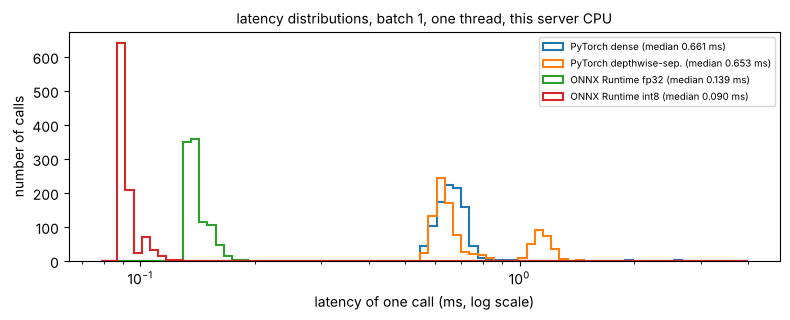

In [2]:
def bench(fn, warmup=50, reps=1000, max_seconds=None):
    for _ in range(warmup):
        fn()
    t, t_begin = [], time.perf_counter()
    for i in range(reps):
        t0 = time.perf_counter_ns(); fn(); t.append(time.perf_counter_ns() - t0)
        if max_seconds and time.perf_counter() - t_begin > max_seconds:
            break                                          # a time budget, so a pathological setting cannot run for minutes
    return np.array(t) / 1e6                               # milliseconds

def summary(t):
    return {"median": np.median(t), "p90": np.percentile(t, 90), "p99": np.percentile(t, 99), "mean": t.mean(), "min": t.min(), "max": t.max()}

def environment():
    cpu = next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), platform.processor()) \
          if os.path.exists("/proc/cpuinfo") else platform.processor()
    return (f"{cpu}; {os.cpu_count()} logical cores visible; {platform.system()} {platform.release()}; Python {platform.python_version()}; "
            f"torch {torch.__version__} ({torch.get_num_threads()} thread); onnxruntime {ort.__version__}")

print("measured on:", environment())
times = {}
with torch.inference_mode():
    for name, f in models.items():
        times[name] = bench(lambda: f(x1n))
table = pd.DataFrame({k: summary(v) for k, v in times.items()}).T
print("\nbatch 1, one thread, 1,000 calls each (milliseconds)")
print(table.round(4).to_string())

plt.figure(figsize=(8, 3.3))
bins = np.geomspace(min(t.min() for t in times.values()) * 0.9, max(np.percentile(t, 99.9) for t in times.values()) * 1.1, 80)
for name, t in times.items():
    plt.hist(t, bins=bins, histtype="step", lw=1.5, label=f"{name} (median {np.median(t):.3f} ms)")
plt.xscale("log"); plt.xlabel("latency of one call (ms, log scale)"); plt.ylabel("number of calls")
plt.title("latency distributions, batch 1, one thread, this server CPU", fontsize=10); plt.legend(fontsize=7); plt.tight_layout(); plt.show()

### 3. Warm-up and cold start
The first calls of a freshly created model are slower: memory is allocated, kernels are chosen and prepared, and caches are cold. A user who opens the app and runs the model once feels this **cold start**; a long video stream mostly sees warm calls. We create new copies of each model and time their first 30 calls.

PyTorch dense      call 1: 0.971 ms | call 2: 0.592 ms | median of calls 11-30: 0.587 ms
ONNX Runtime int8  call 1: 0.396 ms | call 2: 0.126 ms | median of calls 11-30: 0.091 ms
creating the ONNX Runtime session (loading and optimizing the graph) took 2.8 ms before the first call


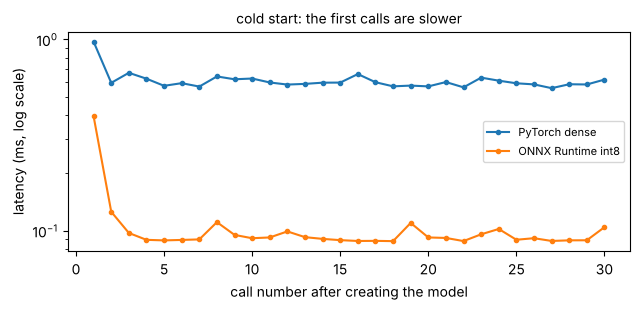

In [3]:
fresh_dense = dense_cnn(); fresh_dense.load_state_dict(dense.state_dict()); fresh_dense.eval()
fresh = {"PyTorch dense": lambda: fresh_dense(x1)}
t0 = time.perf_counter(); s8_new = ort_session(int8_path); load_ms = 1e3 * (time.perf_counter() - t0)
fresh["ONNX Runtime int8"] = lambda: s8_new.run(None, {IN: x1n})
first = {}
with torch.inference_mode():
    for name, f in fresh.items():
        t = []
        for _ in range(30):
            t0 = time.perf_counter_ns(); f(); t.append((time.perf_counter_ns() - t0) / 1e6)
        first[name] = np.array(t)
        print(f"{name:18s} call 1: {t[0]:.3f} ms | call 2: {t[1]:.3f} ms | median of calls 11-30: {np.median(t[10:]):.3f} ms")
print(f"creating the ONNX Runtime session (loading and optimizing the graph) took {load_ms:.1f} ms before the first call")

plt.figure(figsize=(6.5, 3.2))
for name, t in first.items():
    plt.semilogy(range(1, 31), t, "o-", ms=3, label=name)
plt.xlabel("call number after creating the model"); plt.ylabel("latency (ms, log scale)")
plt.title("cold start: the first calls are slower", fontsize=10); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4. The mean, the median and outliers
Background work, interrupts and other programs make a few calls much slower. The **mean** moves with every slow call; the **median** does not. Below we first compare them on the real measurements of section 2. Then, as a **synthetic** illustration, we add a 10 ms delay to 1% of the ONNX Runtime int8 calls, as an occasional pause might do on a phone.

In [4]:
for name, t in times.items():
    print(f"{name:24s} mean {t.mean():.4f} ms, median {np.median(t):.4f} ms, mean/median {t.mean() / np.median(t):.3f}, "
          f"slowest call {t.max():.3f} ms = {t.max() / np.median(t):.1f} x the median")
rng = np.random.default_rng(0)
t = times["ONNX Runtime int8"].copy()
slow = rng.choice(len(t), size=len(t) // 100, replace=False)
t_out = t.copy(); t_out[slow] += 10.0                      # synthetic: 1% of calls delayed by 10 ms
for label, v in [("measured", t), ("with 1% synthetic 10 ms delays", t_out)]:
    s = summary(v)
    print(f"ONNX Runtime int8, {label:31s}: median {s['median']:.4f} ms | mean {s['mean']:.4f} ms | p99 {s['p99']:.4f} ms")

PyTorch dense            mean 0.6864 ms, median 0.6611 ms, mean/median 1.038, slowest call 3.878 ms = 5.9 x the median
PyTorch depthwise-sep.   mean 0.7790 ms, median 0.6525 ms, mean/median 1.194, slowest call 1.469 ms = 2.3 x the median
ONNX Runtime fp32        mean 0.1415 ms, median 0.1386 ms, mean/median 1.021, slowest call 0.326 ms = 2.4 x the median
ONNX Runtime int8        mean 0.0926 ms, median 0.0897 ms, mean/median 1.033, slowest call 0.272 ms = 3.0 x the median
ONNX Runtime int8, measured                       : median 0.0897 ms | mean 0.0926 ms | p99 0.1145 ms
ONNX Runtime int8, with 1% synthetic 10 ms delays : median 0.0897 ms | mean 0.1926 ms | p99 0.3698 ms


### 5. Threads and batch size
More threads can split one call's work across cores; a bigger batch shares each weight read among several inputs (session 1). Both trade **latency** (time until one answer) against **throughput** (answers per second). This machine has 4 cores shared with other jobs, so expect noisy multi-thread results (each setting gets at most 1.5 s of timing); a phone also mixes fast and slow cores (Arm's big.LITTLE design), and threads that land on a slow core slow down the whole call.

            model  threads  batch  calls  ms_per_call  ms_per_image
    PyTorch dense        1      1    100       0.5922        0.5922
ONNX Runtime int8        1      1    100       0.0910        0.0910
    PyTorch dense        1     32     40      14.6316        0.4572
ONNX Runtime int8        1     32     40       2.4991        0.0781
    PyTorch dense        2      1    100       0.5701        0.5701
ONNX Runtime int8        2      1    100       0.0824        0.0824
    PyTorch dense        2     32     40       8.0850        0.2527
ONNX Runtime int8        2     32     40       1.7008        0.0532
    PyTorch dense        4      1     14      96.3603       96.3603
ONNX Runtime int8        4      1    100       0.0940        0.0940
    PyTorch dense        4     32      9     171.9917        5.3747
ONNX Runtime int8        4     32     40      10.6097        0.3316



one thread: time per call and throughput against batch size
model  ONNX Runtime fp32  ONNX Runtime int8  PyTorch dense  PyTorch depthwise-sep.
batch                                                                             
1                 7245.0            11052.0         1649.0                  1536.0
4                 7496.0            12206.0         1786.0                  2085.0
16                7368.0            12581.0         2070.0                  2230.0
64                5066.0            12277.0         2149.0                  2432.0


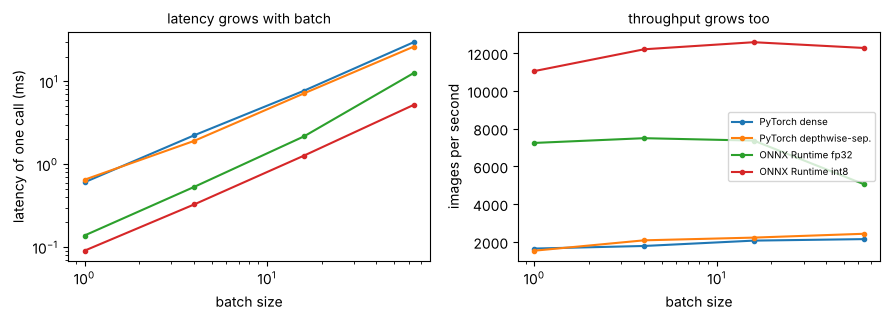

In [5]:
rows = []
with torch.inference_mode():
    for threads in [1, 2, 4]:
        torch.set_num_threads(threads); s8_t = ort_session(int8_path, threads)
        for batch in [1, 32]:
            xb = Xte[:batch]; xbn = xb.numpy()
            for name, f in [("PyTorch dense", lambda: dense(xb)), ("ONNX Runtime int8", lambda: s8_t.run(None, {IN: xbn}))]:
                tt = bench(f, warmup=5, reps=100 if batch == 1 else 40, max_seconds=1.5)
                rows.append(dict(model=name, threads=threads, batch=batch, calls=len(tt), ms_per_call=np.median(tt), ms_per_image=np.median(tt) / batch))
torch.set_num_threads(1)
thr = pd.DataFrame(rows)
print(thr.round(4).to_string(index=False))

rows = []
with torch.inference_mode():
    for batch in [1, 4, 16, 64]:
        xbn = Xte[:batch].numpy()
        for name, f in models.items():
            med = np.median(bench(lambda: f(xbn), warmup=5, reps=60 if batch < 64 else 20))
            rows.append(dict(model=name, batch=batch, ms_per_call=med, images_per_s=batch / med * 1e3))
bat = pd.DataFrame(rows)
print("\none thread: time per call and throughput against batch size")
print(bat.pivot(index="batch", columns="model", values="images_per_s").round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for name in models:
    b = bat[bat.model == name]
    ax[0].loglog(b.batch, b.ms_per_call, "o-", ms=3, label=name); ax[1].semilogx(b.batch, b.images_per_s, "o-", ms=3, label=name)
ax[0].set_xlabel("batch size"); ax[0].set_ylabel("latency of one call (ms)"); ax[0].set_title("latency grows with batch", fontsize=10)
ax[1].set_xlabel("batch size"); ax[1].set_ylabel("images per second"); ax[1].set_title("throughput grows too", fontsize=10)
ax[1].legend(fontsize=7, loc="center right"); plt.tight_layout(); plt.show()

### 6. Run-to-run variation and a bootstrap interval
A single benchmark run can mislead: the machine's state changes between runs. We repeat a short benchmark 10 times, each time timing ONNX Runtime float32 and int8 in turn (interleaved, so slow periods hit both), and record the ratio of their medians for each run. A **bootstrap** over the 10 runs (resample runs with replacement, recompute the mean ratio, 2,000 times; Course 2 session 7) gives a 95% interval for the speed-up.

In [6]:
ratios, med32, med8 = [], [], []
for run in range(10):
    a = bench(lambda: s32.run(None, {IN: x1n}), warmup=20, reps=200)
    b = bench(lambda: s8.run(None, {IN: x1n}), warmup=20, reps=200)
    med32.append(np.median(a)); med8.append(np.median(b)); ratios.append(np.median(a) / np.median(b))
ratios = np.array(ratios)
print("per-run median latency, float32 (ms):", np.round(med32, 4))
print("per-run median latency, int8 (ms):   ", np.round(med8, 4))
print("per-run speed-up of int8 over float32:", np.round(ratios, 3))
boot = np.array([rng.choice(ratios, size=len(ratios), replace=True).mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"mean speed-up {ratios.mean():.3f}, 95% bootstrap interval {lo:.3f} to {hi:.3f}; "
      f"single runs ranged from {ratios.min():.3f} to {ratios.max():.3f}")

per-run median latency, float32 (ms): [0.2112 0.2175 0.2202 0.1408 0.1393 0.1384 0.142  0.1398 0.1382 0.1404]
per-run median latency, int8 (ms):    [0.1517 0.1528 0.1467 0.0914 0.0924 0.0914 0.091  0.0915 0.0917 0.1221]
per-run speed-up of int8 over float32: [1.393 1.424 1.502 1.54  1.508 1.515 1.561 1.528 1.507 1.149]
mean speed-up 1.463, 95% bootstrap interval 1.380 to 1.519; single runs ranged from 1.149 to 1.561


### 7. End-to-end time
A user waits for the whole pipeline, not just the model: here, turning the raw 8 × 8 digit into a normalized 32 × 32 image, running the model, and picking the answer. On a phone the pipeline may also include camera capture, resizing and drawing the result. We time the pre-processing alone, the model alone and the whole pipeline for the fastest model, calling the three in turn (measured one after another, a noisy machine can even make the part look slower than the whole).

In [7]:
raw = X8te[:1]
def pipeline():
    x = preprocess(raw)                                     # pre-processing
    logits = s8.run(None, {IN: x})[0]                      # the model
    return int(logits.argmax())                            # post-processing
def bench_interleaved(fns, warmup=50, reps=1000):        # call the functions in turn, so slow periods hit all of them
    for f in fns.values():
        for _ in range(warmup):
            f()
    t = {k: np.empty(reps) for k in fns}
    for i in range(reps):
        for k, f in fns.items():
            t0 = time.perf_counter_ns(); f(); t[k][i] = time.perf_counter_ns() - t0
    return {k: v / 1e6 for k, v in t.items()}
e2e = bench_interleaved({"pre-processing only": lambda: preprocess(raw), "model only": lambda: s8.run(None, {IN: x1n}),
                         "end to end": pipeline})
print("ONNX Runtime int8, medians of 1,000 interleaved calls: " + ", ".join(f"{k} {np.median(v):.4f} ms" for k, v in e2e.items()))
print(f"the model is {100 * np.median(e2e['model only']) / np.median(e2e['end to end']):.0f}% of the end-to-end time")
print(f"runtime so far {time.time() - t_start:.0f} s")

ONNX Runtime int8, medians of 1,000 interleaved calls: pre-processing only 0.0289 ms, model only 0.0943 ms, end to end 0.1273 ms
the model is 74% of the end-to-end time
runtime so far 27 s


### 8. Energy and battery, from stated assumptions
Energy is power × time: a part that draws $P$ watts for $t$ seconds uses $E = P t$ joules. This server cannot measure a phone's power; phones are measured with an external power monitor that replaces the battery, while the screen and radios are held fixed. So every number below rests on **assumptions**, which we state:

* the extra power of the processor while it runs the model: 0.5, 1 or 2 W (round numbers for illustration, not measurements);
* the phone's time per inference: 1, 5 or 20 ms (not this server's times);
* the battery: 5,000 mAh at 3.85 V, that is $5 \times 3.85 = 19.25$ Wh $= 69{,}300$ J.

Note "race to idle": a faster unit that draws more power can still use less energy, because it finishes sooner.

In [8]:
BATTERY_J = 5.0 * 3.85 * 3600                               # 5,000 mAh x 3.85 V, in joules (assumption)
rows = []
for p_w in [0.5, 1.0, 2.0]:                                 # assumed extra power, watts
    for t_ms in [1, 5, 20]:                                 # assumed phone latency, milliseconds
        e = p_w * t_ms / 1e3                                # joules per inference
        rows.append(dict(power_W=p_w, latency_ms=t_ms, energy_mJ=1e3 * e, inferences_per_1pct_battery=round(0.01 * BATTERY_J / e),
                         pct_battery_per_hour_at_10_per_s=100 * e * 10 * 3600 / BATTERY_J))
en = pd.DataFrame(rows)
print(f"battery (assumed): {BATTERY_J:,.0f} J")
print(en.round(3).to_string(index=False))
cpu = 1.0 * 20e-3; npu = 2.0 * 2e-3                          # assumed: CPU 1 W for 20 ms, NPU 2 W for 2 ms
print(f"\nrace to idle (assumed numbers): CPU {1e3 * cpu:.0f} mJ against NPU {1e3 * npu:.0f} mJ per inference, "
      f"although the NPU draws twice the power")

battery (assumed): 69,300 J
 power_W  latency_ms  energy_mJ  inferences_per_1pct_battery  pct_battery_per_hour_at_10_per_s
     0.5           1        0.5                      1386000                             0.026
     0.5           5        2.5                       277200                             0.130
     0.5          20       10.0                        69300                             0.519
     1.0           1        1.0                       693000                             0.052
     1.0           5        5.0                       138600                             0.260
     1.0          20       20.0                        34650                             1.039
     2.0           1        2.0                       346500                             0.104
     2.0           5       10.0                        69300                             0.519
     2.0          20       40.0                        17325                             2.078

race to idle (assumed

### 9. Exercises

In [9]:
# TODO: a confidence interval for p99. Bootstrap the 1,000 measured calls of "PyTorch dense" from section 2
# (resample the calls, recompute the 99th percentile, 2,000 times) and report a 95% interval for its p99. Then do the
# same with only 100 calls. How many calls do you need before p99 is worth reporting?
def p99_interval(t, n_boot=2000):
    return None          # replace with your code

r = p99_interval(times["PyTorch dense"])
print("not done yet" if r is None else r)

not done yet


In [10]:
# TODO: the depthwise-separable model has 6.6 times fewer MACs than the dense one. Export it to ONNX as in section 1,
# benchmark it in ONNX Runtime (float32) with the harness, and fill in a fair comparison table of the two models in the
# same runtime: accuracy, MACs, median and p99 latency, batch 1 and 32. Does the MAC saving become a time saving?
ds_onnx_results = None   # replace with a pandas DataFrame
print("not done yet" if ds_onnx_results is None else ds_onnx_results)

not done yet


### What to notice
(Written from the saved run. Accuracies, MACs, the energy table and (to within a few bytes) the file sizes will match yours; every timing comes from a shared server CPU and will differ, sometimes a lot.)

1. **Two changes, two effects.** On the same float32 model, moving from PyTorch to ONNX Runtime cut the median batch-1 latency from 0.6611 ms to 0.1386 ms, and static int8 cut it further to 0.0897 ms. Accuracy stayed 0.9778 in ONNX Runtime float32 (a faithful conversion) and became 0.9756 in int8 (one test image of 450). A fair report names both changes instead of crediting quantization with the whole speed-up. The int8 file is 132,701 bytes against 466,411.
2. **Fewer MACs did not mean faster.** The depthwise-separable CNN has 6.6 times fewer MACs (1,474,560 against 9,752,576) and was slightly more accurate (0.9867), but in PyTorch at batch 1 its median was 0.6525 ms against 0.6611 ms for the dense CNN, almost the same, and at batch 64 it processed 2,432 images per second against 2,149, only 13% more. Session 2's warning holds: count MACs, but measure time.
3. **Latency has a tail, so report percentiles.** The depthwise-separable CNN had a median of 0.6525 ms but a p90 of 1.1664 ms, so its mean (0.7790 ms) was 19% above its median. The dense CNN's p99 was 1.5892 ms, 2.4 times its median. When we added a synthetic 10 ms delay to 1% of the int8 calls, the median did not move (0.0897 ms) while the mean doubled (0.0926 to 0.1926 ms) and p99 more than tripled (0.1145 to 0.3698 ms).
4. **The first call is slow.** PyTorch's first call took 0.971 ms against about 0.587 ms later; ONNX Runtime's first call took 0.396 ms against 0.091 ms later, after 2.8 ms to create the session. A user who runs a model once feels this cold start.
5. **More threads can be much slower.** On this shared 4-core machine, two threads helped at batch 32: PyTorch went from 14.63 to 8.09 ms per call and ONNX Runtime int8 from 2.50 to 1.70 ms. With four threads, PyTorch took 96.36 ms per call at batch 1 instead of 0.59 ms, and ONNX Runtime int8 took 10.61 ms at batch 32: most likely their worker threads had to wait for cores that other programs were using. On a phone, test each thread count; never assume that more is faster.
6. **Batching trades latency for throughput.** ONNX Runtime int8 rose from 11,052 to 12,277 images per second between batch 1 and batch 64, but one call at batch 64 takes about 5.2 ms (64 ÷ 12,277 s) instead of 0.09 ms. An app answering one user at a time needs the batch-1 latency. (ONNX Runtime float32 fell to 5,066 images per second at batch 64 in this run, probably disturbance from other jobs rather than a real effect.)
7. **Repeat runs, and give an interval.** In 10 runs, int8 was between 1.149 and 1.561 times faster than float32. In the first three runs both models were slower (probably other jobs on the machine), and in the last run only int8 hit a slow period, so a single run could have reported almost any speed-up in that range. The mean speed-up was 1.463, with a 95% bootstrap interval of 1.380 to 1.519.
8. **Measure what the user waits for.** Measured in turn, pre-processing took 0.0289 ms, the model 0.0943 ms and the whole pipeline 0.1273 ms, so the model was 74% of the end-to-end time. On a phone, camera capture and resizing can take far longer than a model this small.
9. **Energy needs a power measurement; until then, state the assumptions.** At an assumed 1 W for 5 ms, one inference uses 5 mJ, so 1% of a 69,300 J battery pays for 138,600 inferences, and 10 inferences per second for an hour use 0.26% of the battery. In the race-to-idle example, the CPU used 20 mJ and an NPU that draws twice the power used 4 mJ. The screen, camera and radios also draw power, so measure the whole phone with a power monitor before making claims.